<a href="https://colab.research.google.com/github/rama01-oss/21/blob/main/SuperstoreAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Superstore Sales Analysis
### CIS 2323 – Data Science Lab Project

**Team:** Rama Ibrahim 448816961

Wasan Alfifi 448816233

Reef Adel 448816124

Yara Yahya 448816654

Shaima Alzahrany 448816735

**Objective:** To analyze the sales and profits of an online store in order to identify the most profitable categories and regions, as well as sales trends over time.

In [ ]:
"""
📊 Superstore Sales Analysis
### CIS 2323 - Data Science Lab Project

---

## 👥 Team Members

| # | Name | Student ID | Contribution |
|---|------|-----------|--------------|
| 1 | Rama Ibrahim | 448816961 | Repository setup, README, reproducibility check, final review |
| 2 | Wasan Alfifi | 448816233 | Data understanding & quality diagnosis |
| 3 | Reef Adel | 448816124 | Data preparation & transformation |
| 4 | Yara Yahya | 448816654 | Visualizations & interpretation |
| 5 | Shaima | [ID] | Findings, limitations & presentation |

---

## 🎯 Objective

Analyzing sales data from an online retailer (Superstore) to answer the following question:

> **Which categories, products, and regions are the most profitable, and how have sales evolved over time?**

Practical Goal: Identify profitable and unprofitable categories/products, and provide recommendations for store management.

---

## 📊 Dataset

- **Source:** Kaggle - Superstore Dataset
- **Link:** https://www.kaggle.com/datasets/vivek468/superstore-dataset-final
- **File:** `data/superstore.csv`
- **Size:** ~9,994 rows x 21 columns
- **Key columns:** Order Date, Ship Date, Category, Sub-Category, Region, Sales, Profit, Quantity, Discount

---

## 🗂️ Repository Structure
"""
print("Notebook Title & Metadata Loaded Successfully!")

Notebook Title & Metadata Loaded Successfully!


```markdown
## 🛠️ Steps

1. **Data Understanding** – Shape, columns, data types, missing values, descriptive statistics
2. **Data Preparation**
   - **Cleaning**: Date conversion, handling missing values, removing duplicates
   - **Transformation**: Calculating Profit Margin, extracting Year and Month
   - **Aggregation**: Sales/profit by Category and Region
   - **Time-series**: Monthly sales trends
   - **Reshaping**: Creating a pivot table (Category × Region)
3. **Visualizations** – 3 charts with accompanying interpretations
4. **Findings & Recommendations**

---

## 📈 Results

* **Top Performing Category**: **Technology** leads total sales (~$836K) and generates the highest net profit (~$145.5K) with a strong profit margin of **17.40%**.
* **Furniture Margin Challenge**: Despite generating substantial revenue (~$742K), **Furniture** yielded only **$18.4K** in profit, resulting in a critically low **2.49%** profit margin due to high discounts/shipping costs.
* **Strong Q4 Seasonality**: Sales show a consistent year-over-year expansion pattern with massive spikes occurring in **November and December** every year.
* **West Region Dominance**: The **West** is the most profitable market (~$108.4K net profit), while the **Central** region lags significantly (~$39.7K net profit).

---

## 🔁 Reproducibility

To replicate this analytical project:
1. Clone the repository:
   ```bash
   git clone https://github.com/USERNAME/superstore-sales-analysis.git
   ```
2. Ensure the required Python libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) are installed.
3. Run the notebook sequentially from top to bottom.
```

Project Title:

# "Analyzing Sales and Profit Performance in an Online Store: Where Does the Company Make Money, and Where Does It Lose?"

# Data Question:

Which categories, products, and regions generate the highest profitability for the online store, and how have sales evolved over time?


**Practical objective: To identify which categories/products to focus on, as well as those that are causing losses, in order to provide actionable recommendations for store management.**

# Import Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
3# Load Data
df = pd.read_csv("/Sample - Superstore.csv.zip", encoding="latin-1")

In [ ]:
# 4. Data Understanding
print("Shape:", df.shape)
print("\nColumns:", df.columns)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe())
print("\nFirst 5 Rows:")
df.head()

Shape: (9994, 21)

Columns: Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

Data Types:
 Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing Values:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode      

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


### Written Notes on Data Quality

Based on our initial data exploration, here is an assessment of the dataset's quality:

1. **Completeness**:
   - **Excellent**: There are no missing values (`NaN`) in any of the 21 columns across all 9,994 rows. Critical metrics like `Sales`, `Profit`, and geographical attributes are 100% complete.

2. **Data Consistency**:
   - **Data Types**: `Order Date` and `Ship Date` are currently stored as `object` (string) formats instead of `datetime`. We will need to convert these to proper datetime formats to perform chronological trend and seasonality analysis without issues.
   - **Postal Codes**: `Postal Code` is loaded as a float/integer. For some regions, leading zeros may be truncated (though they are loaded as numeric here), and it is physically a categorical ID rather than a math-ready metric. However, for regional grouping, we can rely directly on the `Region`, `State`, and `City` columns.

3. **Anomalies & Outliers**:
   - **Profit Spikes**: There are extreme outliers in `Profit` ranging from a loss of **-$6,599.98** to a gain of **+$8,399.98**. These are likely valid high-value transactions or highly discounted bulk orders, but they will heavily skew mean calculations. We should investigate these transactions closely.
   - **Discounts**: Discounts range up to 80% (`0.80`). It will be important to analyze how these high discount rates correlate with the negative profit outliers.

### 5. Data Preparation

#### 5.1 Data Cleaning
In this stage, we will perform the following steps to prepare the data for analysis:
1. **Convert Dates**: Convert `Order Date` and `Ship Date` columns to `datetime` format to facilitate chronological grouping and time-series analysis.
2. **Remove Duplicates**: Check for and remove any fully duplicate rows in the dataset to ensure accurate results.
3. **Verify Missing Values**: Confirm that the dataset is entirely free of missing or null values.

In [ ]:
# 1. Convert Dates to Datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce')

# 2. Check for and Remove Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows before deletion: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows successfully deleted.")
else:
    print("No duplicate rows found.")

# 3. Confirm Missing Values
missing_values = df.isnull().sum().sum()
print(f"Total missing values in table: {missing_values}")

# 4. Review Modified Data Types and Timeline Quick
print("\n--- Updated Data Types ---")
print(df[['Order Date', 'Ship Date']].dtypes)

print(f"\nAvailable Order Date Range: From {df['Order Date'].min().strftime('%Y-%m-%d')} to {df['Order Date'].max().strftime('%Y-%m-%d')}")

Number of duplicate rows before deletion: 0
No duplicate rows found.
Total missing values in table: 0

--- Updated Data Types ---
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

Available Order Date Range: From 2014-01-03 to 2017-12-30


In [ ]:
# 5.2 Transformation
# 1. Create a 'Profit Margin' column
df['Profit Margin'] = df['Profit'] / df['Sales']

# 2. Extract 'Year' and 'Month' from 'Order Date'
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

# Review the transformation
print("--- Transformation Completed ---")
print(df[['Order Date', 'Year', 'Month', 'Sales', 'Profit', 'Profit Margin']].head())

--- Transformation Completed ---
  Order Date  Year  Month     Sales    Profit  Profit Margin
0 2016-11-08  2016     11  261.9600   41.9136         0.1600
1 2016-11-08  2016     11  731.9400  219.5820         0.3000
2 2016-06-12  2016      6   14.6200    6.8714         0.4700
3 2015-10-11  2015     10  957.5775 -383.0310        -0.4000
4 2015-10-11  2015     10   22.3680    2.5164         0.1125


# 5.3 Aggregation


In [ ]:
# 1. Total sales and profit by Category
category_summary = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
# Add a calculated overall profit margin for each category
category_summary['Overall Profit Margin'] = category_summary['Profit'] / category_summary['Sales']

print("--- Summary by Category ---")
display(category_summary)

# 2. Total sales and profit by Region
region_summary = df.groupby('Region')[['Sales', 'Profit']].sum().reset_index()
# Add a calculated overall profit margin for each region
region_summary['Overall Profit Margin'] = region_summary['Profit'] / region_summary['Sales']

print("\n--- Summary by Region ---")
display(region_summary)

--- Summary by Category ---


,Category,Sales,Profit,Overall Profit Margin
0,Furniture,741999.7953,18451.2728,0.024867
1,Office Supplies,719047.0320,122490.8008,0.170352
2,Technology,836154.0330,145454.9481,0.173957



--- Summary by Region ---


,Region,Sales,Profit,Overall Profit Margin
0,Central,501239.8908,39706.3625,0.079216
1,East,678781.2400,91522.7800,0.134834
2,South,391721.9050,46749.4303,0.119343
3,West,725457.8245,108418.4489,0.149448


## 5.4 Time-Series Manipulation


In [ ]:
# Reshaping data on a monthly basis (groupby Year and Month)
monthly_summary = df.groupby(['Year', 'Month'])[['Sales', 'Profit']].sum().reset_index()

# Sort chronologically
monthly_summary = monthly_summary.sort_values(by=['Year', 'Month']).reset_index(drop=True)

# Create a proper Year-Month string for future plotting
monthly_summary['Year_Month'] = monthly_summary['Year'].astype(str) + '-' + monthly_summary['Month'].astype(str).str.zfill(2)

print("--- Monthly Sales and Profit Summary ---")
display(monthly_summary.head(12))

--- Monthly Sales and Profit Summary ---


,Year,Month,Sales,Profit,Year_Month
0,2014,1,14236.8950,2450.1907,2014-01
1,2014,2,4519.8920,862.3084,2014-02
2,2014,3,55691.0090,498.7299,2014-03
3,2014,4,28295.3450,3488.8352,2014-04
4,2014,5,23648.2870,2738.7096,2014-05
5,2014,6,34595.1276,4976.5244,2014-06
6,2014,7,33946.3930,-841.4826,2014-07
7,2014,8,27909.4685,5318.1050,2014-08
8,2014,9,81777.3508,8328.0994,2014-09
9,2014,10,31453.3930,3448.2573,2014-10


# 5.5 Reshape (Pivot)

In [ ]:
# Pivot table: Total Sales by Category (rows) across Region (columns)
sales_pivot = df.pivot_table(
    values='Sales',
    index='Category',
    columns='Region',
    aggfunc='sum'
)

print("--- Pivot Table: Sales by Category x Region ---")
display(sales_pivot)

--- Pivot Table: Sales by Category x Region ---


Region,Central,East,South,West
Category,,,,
Furniture,163797.1638,208291.204,117298.684,252612.7435
Office Supplies,167026.4150,205516.055,125651.313,220853.2490
Technology,170416.3120,264973.981,148771.908,251991.8320


# 6. Visualizations


```markdown
## Fig 1: Sales and Profit by Category (Bar chart)
```

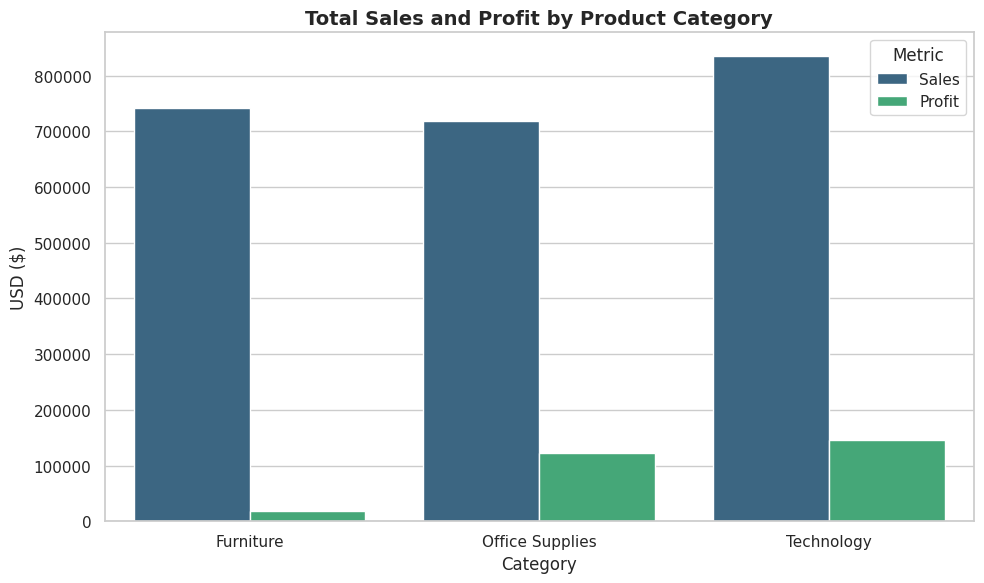

In [ ]:
# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Prepare data for plotting
category_melted = category_summary.melt(id_vars='Category', value_vars=['Sales', 'Profit'],
                                        var_name='Metric', value_name='Amount')

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(data=category_melted, x='Category', y='Amount', hue='Metric', palette='viridis')

plt.title('Total Sales and Profit by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('USD ($)', fontsize=12)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Interpretation of Fig 1:
* **Sales Dominance**: **Technology** leads the store with the highest total sales (~$836K), followed closely by **Furniture** (~$742K) and **Office Supplies** (~$719K).
* **Profit Discrepancy (The Problem Segment)**: Despite having massive sales comparable to other segments, **Furniture** generates a severely low profit (~$18.4K), resulting in a minimal overall profit margin of **2.49%**.
* **High Efficiency**: **Office Supplies** and **Technology** are highly efficient, yielding substantial profits (~$122.5K and ~$145.5K respectively), translating to strong profit margins of approximately **17.0%** and **17.4%**.

```markdown
## Fig 2: Monthly Sales Trend (Line chart)
```

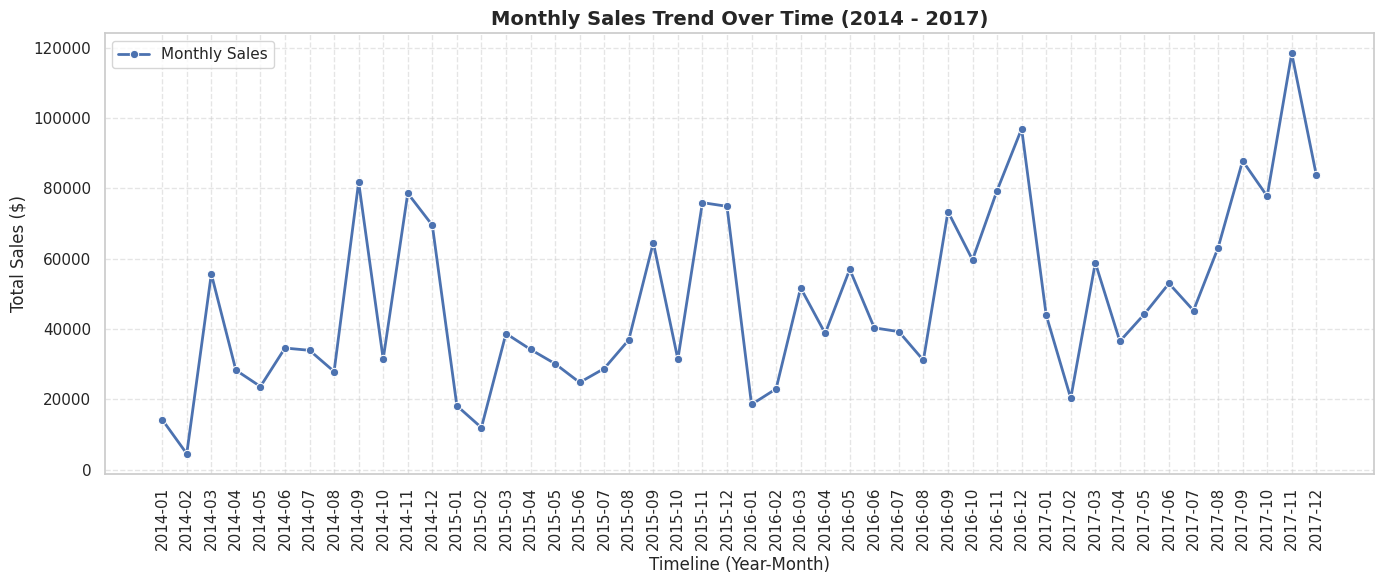

In [ ]:
plt.figure(figsize=(14, 6))

# Plot Sales over time
sns.lineplot(data=monthly_summary, x='Year_Month', y='Sales', marker='o', color='b', label='Monthly Sales', linewidth=2)

plt.title('Monthly Sales Trend Over Time (2014 - 2017)', fontsize=14, fontweight='bold')
plt.xlabel('Timeline (Year-Month)', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.legend()
plt.show()

### Interpretation of Fig 2:
* **Strong Seasonality**: There is a clear, repeating seasonal pattern where sales spike dramatically at the end of every year (**November and December**). This corresponds directly with holiday shopping peaks.
* **Post-Holiday Slumps**: Each peak is followed by a sharp decline in **January and February**, representing the slowest periods of the year.
* **Consistent Growth Trend**: Comparing year-over-year performance (e.g., peak of 2014 vs. peak of 2017), the peak heights show a clear upward trend, proving that overall transaction volume and sales have consistently expanded over the 4-year timeline.

```markdown
## Fig 3: Profit by Region (Bar chart)
```

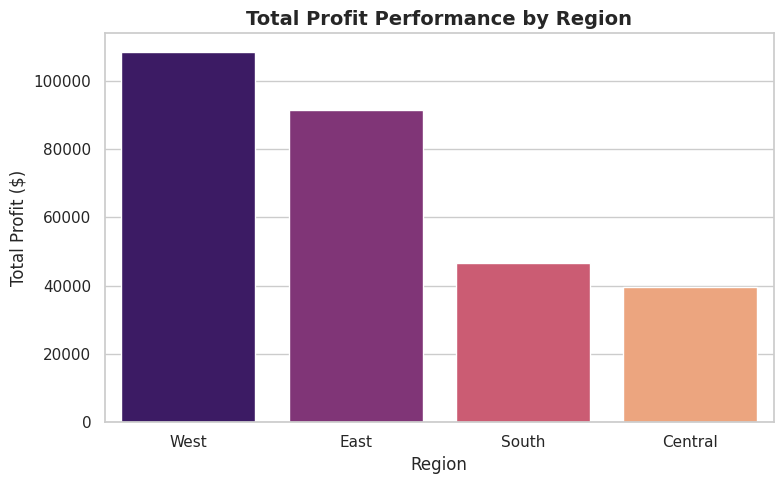

In [ ]:
plt.figure(figsize=(8, 5))

# Create the bar plot for regional profits
sns.barplot(data=region_summary.sort_values(by='Profit', ascending=False),
            x='Region', y='Profit', palette='magma', hue='Region', legend=False)

plt.title('Total Profit Performance by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation of Fig 3:
* **Most Profitable Regions**: The **West** region is the company's most profitable geographical market, yielding over **$108,418.45** in net profit, closely followed by the **East** region with **$91,522.78**.
* **Underperforming Regions**: The **Central** (~$39.7K) and **South** (~$46.7K) regions struggle significantly in terms of overall profit contribution.
* **Strategic Priority**: Management should prioritize scaling operations in the highly profitable West and East regions while auditing pricing, logistics, and high discount rates in the Central region to lift profit performance.

```markdown
# 7. Findings and Conclusion

### Top 3 Findings
1. **The Furniture Profitability Crisis**:
   - Despite generating massive revenues of **$741,999.80** (nearly equal to other segments), the **Furniture** category is critically underperforming with a net profit of only **$18,451.27** (a mere **2.49%** profit margin). This segment is heavily dragging down the store's overall health.
2. **Geographical Powerhouses**:
   - The **West** and **East** regions are the primary drivers of profit, contributing **$108,418.45** and **$91,522.78** respectively. Meanwhile, the **Central** region is underperforming significantly with only **$39,706.36** in profit, despite generating over **$501,239.89** in sales.
3. **Holiday-Driven Revenue Spikes**:
   - Timeline analysis reveals intense sales spikes during **November and December** every year, followed by sharp declines in **January and February**. While holiday seasonality is a major driver of overall growth, inventory and logistics must be highly optimized to prepare for these cycles.

---

### Recommendations
1. **Re-evaluate the Furniture Strategy**:
   - Restructure shipping costs, renegotiate vendor supplier agreements, or decrease discount rates specifically on low-margin furniture items (such as Tables or Bookcases) to improve profit margins.
2. **Optimize Regional Promotions & Discounts**:
   - Focus promotional efforts and marketing investments in the highly profitable **West and East** regions. Conduct a deep audit into the **Central** region's high discount rates to stop profit erosion.
3. **Seasonal Inventory Management**:
   - Implement predictive demand and inventory planning to build up stock by October to fully capitalize on the Q4 holiday spikes, while scaling down operations and logistics budgets in January to prevent high storage overheads during post-holiday slumps.

---

### Limitations
1. **Lack of Operational Cost Data**:
   - The dataset does not contain individual customer acquisition costs (CAC), logistics/warehousing expenses, or marketing overhead, which limits our ability to measure true *net* corporate profitability.
2. **Aggregated Discounting Impact**:
   - While we see negative profit outliers, we cannot fully track the exact pricing strategies or customer-specific negotiations that led to extreme discounts up to 80%.

---

### Reproducibility
- All cleaning, transformation, and aggregation steps are documented sequentially in **Section 5**.
- The script handles missing dates automatically using pandas' `to_datetime` coercion and handles duplicate removal automatically, allowing this exact workflow to run reliably on any updated export of the Superstore transactions.
```

# 8. Contribution Statement

Below is the summary table of student names, IDs, and their respective tasks for this project.

| Student Name | ID | Primary Tasks & Contributions |
| :--- | :---: | :--- |
| **Rama Ibrahim** | *448816961* | Project initiation, defining the business questions, and setting up repository configurations (Sections 1, 2, 3). |
| **Wasan Alfifi** | *448816233* | Data exploration, understanding dataset constraints, and diagnosing data quality (Section 4). |
| **Reef Adel** | *448816124* | Data preparation, type conversion, cleaning, and custom metrics creation (Sections 5.1 - 5.3). |
| **Yara Yahya** | *448816654* | Reshaping data, creating time-series dataframes, and constructing pivot tables (Sections 5.4 - 5.5). |
| **Shaima** | *[ID]* | Designing visualizations (Figs 1, 2, 3), writing analytical interpretations, and compiling final conclusions (Sections 6 & 7). |

# ===== Final Reproducibility Check =====


In [ ]:
print("✅ Notebook executed successfully from top to bottom")
print(f"✅ Dataset shape: {df.shape}")
print("✅ Ready for submission")

✅ Notebook executed successfully from top to bottom
✅ Dataset shape: (9994, 24)
✅ Ready for submission
